# 06 · Does a resource-utilisation KPI make shared faults detectable?

**Question.** Notebook 05 found that faults confined to one slice are easy to catch, but shared faults are hard. A capacity drop below about 8% was not detected within 30 s. Notebook 04 showed that combining the slices' KPIs more cleverly hardly helps for these faults. So: does **more information** help?

**The new KPI.** Real RANs report **PRB utilisation**, the fraction of the radio resource blocks in use. The simulator's equivalent is the cell-level **utilisation**: bits transmitted divided by bits the server could have sent, per 100 ms window (`SimResult.utilisation`, tested in `tests/test_utilisation.py`). A capacity drop at constant traffic raises it by about $1/\text{factor}$, a direct signature that per-slice delay and throughput only show indirectly.

**Method.** This is the same as notebook 05, with the same seeds, so the "without" arm reproduces its numbers. Three detectors (EWMA on whitened residuals, and CUSUM on raw z-scores and on whitened residuals) are run in three set-ups:
- the 11 KPI streams of notebook 05;
- the same 11 streams plus utilisation;
- utilisation alone (CUSUM, raw).

Every set-up is calibrated by simulation to ARL 1000 windows (100 s), with equalised per-stream thresholds. Then the seven faults are swept over strengths $s \in \{0.03, 0.1, 0.25, 0.5, 1\}$.

**Run it** from the project root (about 8 minutes):

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/06_utilisation_kpi.ipynb
```

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUM, EWMA, StreamModel, stream_array
from slicead.eval import calibrate_per_stream, first_alarms, summarize_delays

SEED = 20261022                      # same seeds as notebook 05
OUT = Path("../results/06_utilisation_kpi")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"06_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"06_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"06_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
SLICES = ["eMBB", "URLLC", "mMTC"]
KPIS = ["throughput_mbps", "latency_ms", "jitter_ms", "loss_pct"]
BASE = [(s, k) for s in SLICES for k in KPIS if not (s == "URLLC" and k == "loss_pct")]
UTIL = ("cell", "utilisation")
ALL = BASE + [UTIL]
TARGET_ARL, CHANGE_S, HORIZON_W = 1000, 10.0, 300
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]

## 1. Utilisation in normal operation

In [2]:
t0 = time.time()
train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
calib = simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1)
print(f"simulated in {time.time() - t0:.0f} s")
model = StreamModel().fit(stream_array(train, ALL))
u = train.utilisation
lat = train.kpi("latency_ms")
corr = [np.corrcoef(u.ravel(), lat[..., s].ravel())[0, 1] for s in range(3)]
util_stats = dict(mean=u.mean(), sd=u.std(), p01=np.percentile(u, 1), p99=np.percentile(u, 99),
                  phi=model.phi[-1], **{f"corr_latency_{n}": c for n, c in zip(SLICES, corr)})
pd.Series(util_stats).round(3)

simulated in 63 s


mean                  0.554
sd                    0.337
p01                   0.178
p99                   1.000
phi                   0.623
corr_latency_eMBB     0.620
corr_latency_URLLC    0.650
corr_latency_mMTC     0.717
dtype: float64

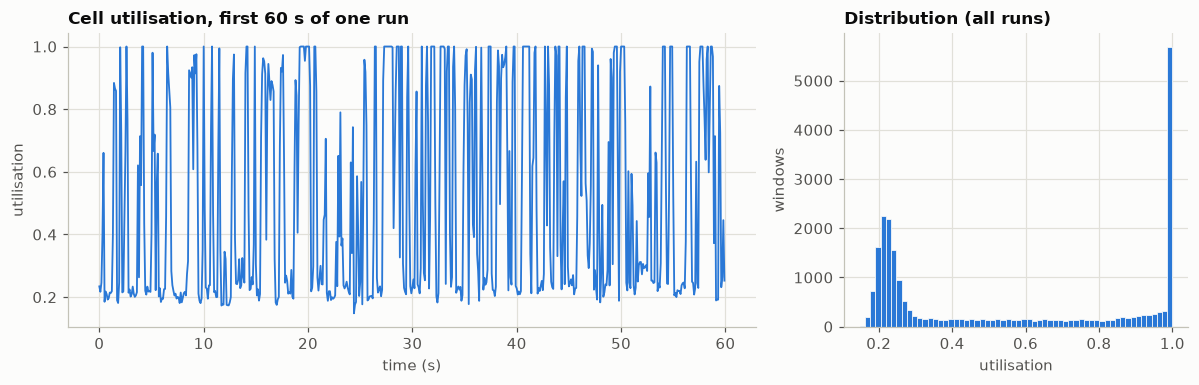

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[2, 1]))
tt = train.time_s[:600]
ax1.plot(tt, u[0, :600], color=BLUE, lw=1.2)
ax1.set_xlabel("time (s)"); ax1.set_ylabel("utilisation")
ax1.set_title("Cell utilisation, first 60 s of one run")
ax2.hist(u.ravel(), bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax2.set_xlabel("utilisation"); ax2.set_ylabel("windows")
ax2.set_title("Distribution (all runs)")
fig.tight_layout()
save_fig(fig, "fig1_utilisation_normal")
plt.show()

**What it shows**

- **Utilisation is driven by eMBB's bursts, not by the cell's health.** It sits near 0.2 when eMBB is quiet and is pinned at **1.0** when eMBB bursts: the server is saturated in about a third of all windows. Mean 0.55, sd 0.34, lag-1 autocorrelation 0.62.
- **It is strongly correlated with every slice's latency (0.62–0.72),** so it carries little information the latency streams do not already have.

## 2. Calibration

Each set-up gets its own equalised per-stream thresholds and a final factor for ARL 1000 windows.

In [4]:
SETUPS = {   # name -> (factory, input, streams)
    "EWMA, whitened": (lambda: EWMA(0.2), "whitened"),
    "CUSUM, raw": (lambda: CUSUM(0.5), "raw"),
    "CUSUM, whitened": (lambda: CUSUM(0.5), "whitened"),
}
STREAM_SETS = {"11 KPIs": BASE, "11 KPIs + utilisation": ALL}
idx = {name: [ALL.index(s) for s in streams] for name, streams in STREAM_SETS.items()}
idx["utilisation alone"] = [ALL.index(UTIL)]

Xcal = stream_array(calib, ALL)
Zcal = {"raw": model.standardize(Xcal), "whitened": model.whiten(Xcal)}
calibrated, rows = {}, []
for det_name, (make, inp) in SETUPS.items():
    for set_name in ["11 KPIs", "11 KPIs + utilisation"]:
        det = make()
        c, arl = calibrate_per_stream(det, Zcal[inp][:, :, idx[set_name]], TARGET_ARL)
        calibrated[(det_name, set_name)] = (det, c, inp)
        rows.append(dict(detector=det_name, streams=set_name, factor=c, arl=arl,
                         util_threshold=det.scale[-1] if set_name != "11 KPIs" else np.nan))
det = CUSUM(0.5)
c, arl = calibrate_per_stream(det, Zcal["raw"][:, :, idx["utilisation alone"]], TARGET_ARL)
calibrated[("CUSUM, raw", "utilisation alone")] = (det, c, "raw")
rows.append(dict(detector="CUSUM, raw", streams="utilisation alone", factor=c, arl=arl, util_threshold=det.scale[0]))
pd.DataFrame(rows).round(2)

,detector,streams,factor,arl,util_threshold
0,"EWMA, whitened",11 KPIs,0.99,1000.0,NaN
1,"EWMA, whitened",11 KPIs + utilisation,0.99,1000.0,1.89
2,"CUSUM, raw",11 KPIs,0.95,1000.0,NaN
3,"CUSUM, raw",11 KPIs + utilisation,0.95,1000.0,21.00
4,"CUSUM, whitened",11 KPIs,0.95,1000.0,NaN
5,"CUSUM, whitened",11 KPIs + utilisation,0.97,1000.0,4.07
6,"CUSUM, raw",utilisation alone,1.00,1000.0,14.20


## 3. The sweep, with and without utilisation

In [5]:
SCENARIOS = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
NICE = {"capacity_drop": "capacity drop", "capacity_degradation": "capacity degradation",
        "embb_surge": "eMBB surge", "urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm",
        "urllc_loss_burst": "URLLC loss burst", "urllc_weight_misconfig": "URLLC weight misconfig."}
N_RUNS, N_WINDOWS = 32, 400

def scaled(faults, s):
    return [Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in faults]

rows, util_shift = [], []
t0 = time.time()
for i, (scen, faults) in enumerate(SCENARIOS.items()):
    for j, s in enumerate(STRENGTHS):
        res = simulate(cfg, n_windows=N_WINDOWS, n_runs=N_RUNS, seed=SEED + 100 + 10 * i + j,
                       faults=scaled(faults, s))
        X = stream_array(res, ALL)
        Z = {"raw": model.standardize(X), "whitened": model.whiten(X)}
        pre, post = ~res.labels, res.time_s >= CHANGE_S + 2
        uz = Z["raw"][:, :, -1]
        util_shift.append(dict(scenario=NICE[scen], strength=s,
                               shift_sd=(uz[:, post].mean() - uz[:, pre].mean())))
        for (det_name, set_name), (det, c, inp) in calibrated.items():
            t_alarm, _ = first_alarms(det, Z[inp][:, :, idx[set_name]], c)
            rows.append(dict(scenario=NICE[scen], strength=s, detector=det_name, streams=set_name,
                             **summarize_delays(t_alarm, res.fault_window, HORIZON_W, res.window_s)))
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "sweep.csv", index=False)
util_shift = pd.DataFrame(util_shift)
print(f"sweep simulated and scored in {time.time() - t0:.0f} s")

# consistency check: the "11 KPIs" arm must match notebook 05 (same seeds, same streams)
nb05 = pd.read_csv("../results/05_detectors/sweep.csv")
nb05 = nb05[nb05.thresholds == "equalised"].set_index(["scenario", "strength", "detector"]).delay_mean_s
mine = sweep[sweep.streams == "11 KPIs"].set_index(["scenario", "strength", "detector"]).delay_mean_s
print("max |difference| from notebook 05:", float((mine - nb05.reindex(mine.index)).abs().max()))

sweep simulated and scored in 225 s


max |difference| from notebook 05: 3.552713678800501e-15


In [6]:
print("Shift of utilisation after the fault, in fault-free sd (raw):")
util_shift.pivot(index="scenario", columns="strength", values="shift_sd").round(2)

Shift of utilisation after the fault, in fault-free sd (raw):


strength,0.03,0.10,0.25,0.50,1.00
scenario,,,,,
URLLC loss burst,-0.06,0.08,-0.01,0.02,-0.03
URLLC surge,-0.02,0.02,-0.00,0.05,0.24
URLLC weight misconfig.,0.01,0.07,0.07,-0.05,-0.03
capacity degradation,-0.00,-0.02,-0.05,0.13,0.05
capacity drop,-0.00,0.11,0.18,0.21,0.37
eMBB surge,0.04,-0.02,0.02,0.10,0.16
mMTC storm,0.00,0.00,0.05,0.13,0.41


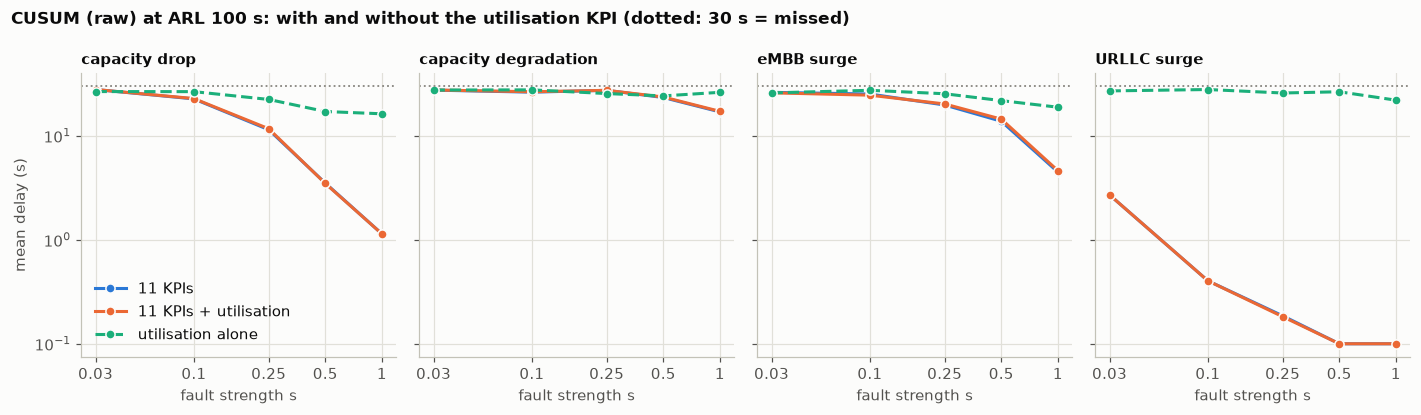

In [7]:
show = ["capacity drop", "capacity degradation", "eMBB surge", "URLLC surge"]
styles = {"11 KPIs": (BLUE, "-"), "11 KPIs + utilisation": (ORANGE, "-"), "utilisation alone": (AQUA, "--")}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
for ax, scen in zip(axes, show):
    g = sweep[(sweep.scenario == scen) & (sweep.detector == "CUSUM, raw")]
    for set_name, (col, ls) in styles.items():
        d = g[g.streams == set_name].sort_values("strength")
        ax.plot(d.strength, d.delay_mean_s, "o", ls=ls, color=col, label=set_name, mec=SURFACE, mew=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(STRENGTHS, [f"{s:g}" for s in STRENGTHS]); ax.minorticks_off()
    ax.axhline(30, color=MUTED, ls=":", lw=1.2)
    ax.set_title(scen, fontsize=10)
    ax.set_xlabel("fault strength s")
axes[0].set_ylabel("mean delay (s)")
axes[0].legend(loc="lower left")
fig.suptitle("CUSUM (raw) at ARL 100 s: with and without the utilisation KPI (dotted: 30 s = missed)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig2_delay_with_utilisation")
plt.show()

In [8]:
piv = sweep.pivot_table(index=["scenario", "strength"], columns=["detector", "streams"], values="delay_mean_s")
piv.round(1)

detector                         CUSUM, raw                        \
streams                             11 KPIs 11 KPIs + utilisation   
scenario                strength                                    
URLLC loss burst        0.03           25.2                  25.2   
                        0.10           24.7                  25.5   
                        0.25           26.8                  26.8   
                        0.50           27.4                  27.0   
                        1.00           26.6                  26.6   
URLLC surge             0.03            2.7                   2.7   
                        0.10            0.4                   0.4   
                        0.25            0.2                   0.2   
                        0.50            0.1                   0.1   
                        1.00            0.1                   0.1   
URLLC weight misconfig. 0.03           21.6                  22.2   
                        0.10            4.1                   4.1   
                        0.25            0.9                   0.9   
                        0.50            0.3                   0.3   
                        1.00            0.1                   0.1   
capacity degradation    0.03           27.5                  27.6   
                        0.10           26.3                  26.5   
                        0.25           27.4                  27.4   
                        0.50           23.3                  23.6   
                        1.00           17.0                  17.2   
capacity drop           0.03           27.9                  27.9   
                        0.10           22.6                  22.8   
                        0.25           11.4                  11.7   
                        0.50            3.5                   3.5   
                        1.00            1.1                   1.1   
eMBB surge              0.03           26.2                  25.9   
                        0.10           25.2                  24.6   
                        0.25           19.8                  20.2   
                        0.50           13.8                  14.5   
                        1.00            4.5                   4.6   
mMTC storm              0.03            0.8                   0.8   
                        0.10            0.2                   0.2   
                        0.25            0.1                   0.1   
                        0.50            0.1                   0.1   
                        1.00            0.1                   0.1   

detector                                           CUSUM, whitened  \
streams                          utilisation alone         11 KPIs   
scenario                strength                                     
URLLC loss burst        0.03                  24.2            26.4   
                        0.10                  23.9            22.7   
                        0.25                  23.7            26.0   
                        0.50                  26.2            27.0   
                        1.00                  27.7            28.2   
URLLC surge             0.03                  27.0             2.7   
                        0.10                  27.9             0.4   
                        0.25                  25.8             0.2   
                        0.50                  26.5             0.1   
                        1.00                  22.0             0.1   
URLLC weight misconfig. 0.03                  28.4            24.9   
                        0.10                  27.2             5.1   
                        0.25                  28.0             0.7   
                        0.50                  23.6             0.2   
                        1.00                  26.7             0.1   
capacity degradation    0.03                  27.5            26.7   
                        0.10                  2

**What the sweep shows: a negative result**

- **Utilisation barely moves under the faults it was meant to reveal.** A full 30% capacity drop shifts it by only 0.37 fault-free sd, and a 3.5% drop ($s = 0.1$) by 0.11 sd. When the server is saturated (eMBB bursting), utilisation is 1.0 with or without the fault. When it is not saturated, the fault's effect is small next to the swing between eMBB's on and off periods.
- **Adding utilisation to the 11 KPIs changes nothing.** Every delay is within Monte Carlo noise of notebook 05; the "11 KPIs" arm reproduces notebook 05 exactly. The capacity drop still needs $s = 0.25$ (11.7 s with utilisation, 11.4 s without), and at $s = 0.1$ neither beats chance.
- **Utilisation alone is a poor detector.** It catches the full capacity drop only after about 16 s, against 1.1 s for the 11 KPIs, and is blind to slice-local faults.

**Why, and what would work instead.** Raw utilisation mixes two things: how much traffic there is, which varies a lot and normally, and how much capacity there is, which a fault changes. A useful capacity indicator must separate them. Two standard RAN quantities do:
- **throughput per resource unit** (delivered bits ÷ utilisation, i.e. spectral efficiency), which directly measures what the server can send;
- **utilisation conditioned on offered load,** for example the residual of utilisation regressed on total offered traffic.

In this simulator the first one is nearly a direct readout of the capacity parameter that the fault changes, so testing it would be partly circular. That caveat has to be stated alongside any such result.

In [9]:
# Export tables and key numbers for report/main.tex
def cell(scen, s, det, streams, col="delay_mean_s"):
    return sweep[(sweep.scenario == scen) & (sweep.strength == s) & (sweep.detector == det)
                 & (sweep.streams == streams)][col].iloc[0]

order = list(NICE.values())
rows = []
for scen in order:
    for s in STRENGTHS:
        r = {"fault": scen, "$s$": f"{s:g}"}
        for set_name, short in [("11 KPIs", "11 KPIs"), ("11 KPIs + utilisation", "+ util."), ("utilisation alone", "util. only")]:
            d, p = cell(scen, s, "CUSUM, raw", set_name), cell(scen, s, "CUSUM, raw", set_name, "detected")
            r[short] = f"{d:.1f}" if p >= 0.995 else f"{d:.1f} ({100 * p:.0f}\\%)"
        rows.append(r)
tab = pd.DataFrame(rows)
tab["fault"] = [f if i == 0 or f != tab.fault[i - 1] else "" for i, f in enumerate(tab.fault)]
save_tex_table(tab, "sweep", "llrrr")

mean_delay = sweep.groupby(["detector", "streams"]).delay_mean_s.mean().unstack()
save_tex_numbers({
    "UtilMean": f"{util_stats['mean']:.2f}", "UtilSd": f"{util_stats['sd']:.2f}", "UtilPhi": f"{util_stats['phi']:.2f}",
    "CapQuarterBase": f"{cell('capacity drop', 0.25, 'CUSUM, raw', '11 KPIs'):.1f}",
    "CapQuarterUtil": f"{cell('capacity drop', 0.25, 'CUSUM, raw', '11 KPIs + utilisation'):.1f}",
    "CapTenthBase": f"{cell('capacity drop', 0.1, 'CUSUM, raw', '11 KPIs'):.1f}",
    "CapTenthUtil": f"{cell('capacity drop', 0.1, 'CUSUM, raw', '11 KPIs + utilisation'):.1f}",
    "CapTenthUtilDet": f"{100 * cell('capacity drop', 0.1, 'CUSUM, raw', '11 KPIs + utilisation', 'detected'):.0f}",
    "EmbbHalfBase": f"{cell('eMBB surge', 0.5, 'CUSUM, raw', '11 KPIs'):.1f}",
    "EmbbHalfUtil": f"{cell('eMBB surge', 0.5, 'CUSUM, raw', '11 KPIs + utilisation'):.1f}",
    "MeanDelayBase": f"{mean_delay.loc['CUSUM, raw', '11 KPIs']:.1f}",
    "MeanDelayUtil": f"{mean_delay.loc['CUSUM, raw', '11 KPIs + utilisation']:.1f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("06_*")))

exported: ['06_numbers.tex', '06_sweep.tex']


## 4. Summary

- **The utilisation KPI is now in the simulator, and it is tested.** It is `SimResult.utilisation`, the cell-level analogue of PRB utilisation.
- **It does not make shared faults detectable.** It is dominated by eMBB's on-off load and pinned at 1.0 whenever the server saturates, so a 30% capacity drop moves it by only 0.37 sd. Adding it to the 11 KPIs changes no delay.
- **The lesson:** "more information" has to be information about *capacity*, separated from *load*. A raw busy-fraction does not qualify; throughput per resource unit or load-conditioned utilisation might, with the circularity caveat above.